In [352]:
library(ggplot2)
library(tidyverse)
library(dplyr)
library(readr)
install.packages("pheatmap")
install.packages("scales")
install.packages("readxl")
library(readxl)
library(scales)
library(pheatmap)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



**- Carregamento dos Dados e a sua Leitura.**

In [353]:
HREmployeeDF<- read.csv2("/content/WA_Fn-UseC_-HR-Employee-Attrition.csv")

In [354]:
head(HREmployeeDF)

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,⋯,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
,<int>,<chr>,<chr>,<int>,<chr>,<int>,<int>,<chr>,<int>,<int>,⋯,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
1,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,⋯,1,80,0,8,0,1,6,4,0,5
2,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,⋯,4,80,1,10,3,3,10,7,1,7
3,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,⋯,2,80,0,7,3,3,0,0,0,0
4,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,⋯,3,80,0,8,3,3,8,7,3,0
5,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,⋯,4,80,1,6,3,3,2,2,2,2
6,32,No,Travel_Frequently,1005,Research & Development,2,2,Life Sciences,1,8,⋯,3,80,0,8,2,2,7,7,3,6


In [355]:
summary(HREmployeeDF)

      Age            Attrition      BusinessTravel   DailyRate     
 Min.   :18.00   Length   :1470   Length   :1470   Min.   : 102.0  
 1st Qu.:30.00   N.unique :   2   N.unique :   3   1st Qu.: 465.0  
 Median :36.00   N.blank  :   0   N.blank  :   0   Median : 802.0  
 Mean   :36.92   Min.nchar:   2   Min.nchar:  10   Mean   : 802.5  
 3rd Qu.:43.00   Max.nchar:   3   Max.nchar:  17   3rd Qu.:1157.0  
 Max.   :60.00                                     Max.   :1499.0  
     Department   DistanceFromHome   Education       EducationField
 Length   :1470   Min.   : 1.000   Min.   :1.000   Length   :1470  
 N.unique :   3   1st Qu.: 2.000   1st Qu.:2.000   N.unique :   6  
 N.blank  :   0   Median : 7.000   Median :3.000   N.blank  :   0  
 Min.nchar:   5   Mean   : 9.193   Mean   :2.913   Min.nchar:   5  
 Max.nchar:  22   3rd Qu.:14.000   3rd Qu.:4.000   Max.nchar:  16  
                  Max.   :29.000   Max.   :5.000                   
 EmployeeCount EmployeeNumber   EnvironmentSatis

            Target 50% Masc./Femin.
- se a empresa (idades colaboradores) é mais nova ou mais velha


**-  Visão Global da Idade dos Colaboradores.**

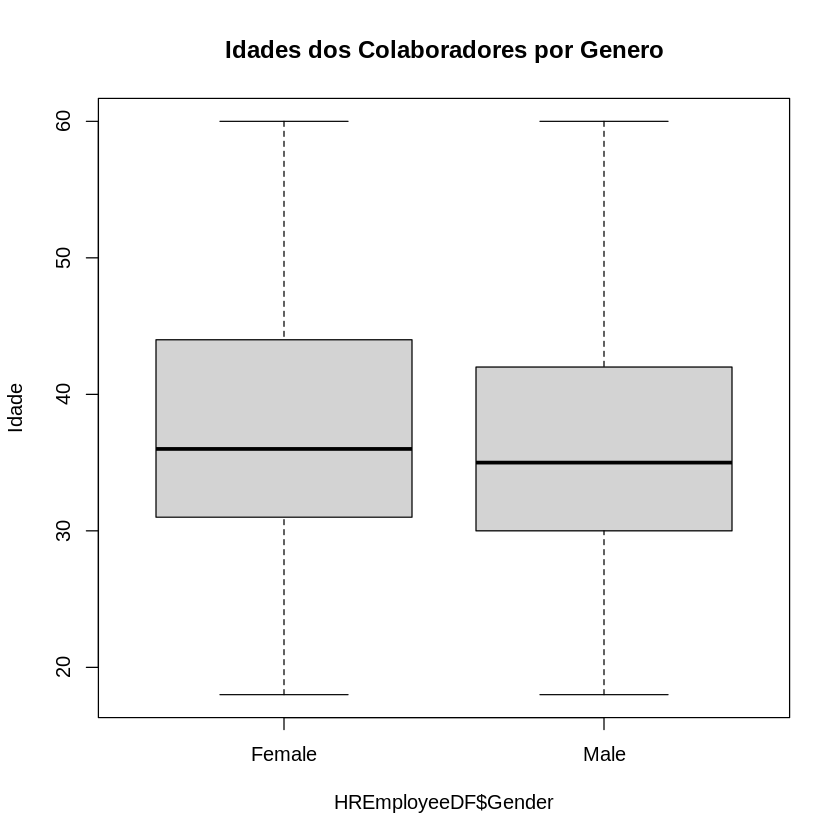

In [356]:
boxplot(HREmployeeDF$Age ~ HREmployeeDF$Gender, main ="Idades dos Colaboradores por Genero",ylab = "Idade")

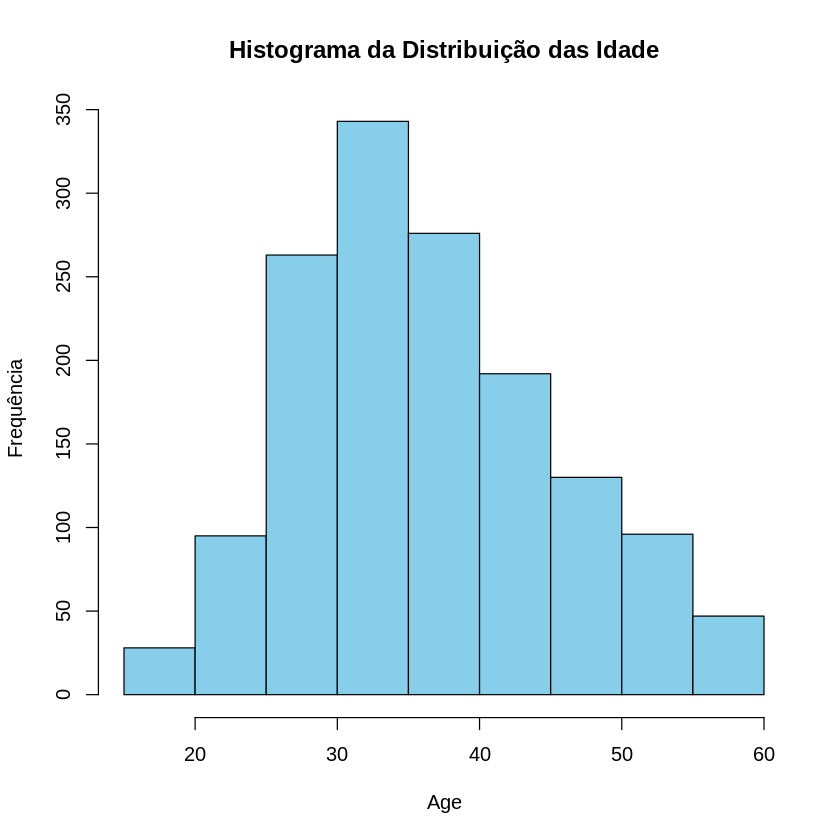

In [357]:
hist(HREmployeeDF$Age, main = "Histograma da Distribuição das Idade", xlab = "Age", ylab = "Frequência", col = "skyblue")

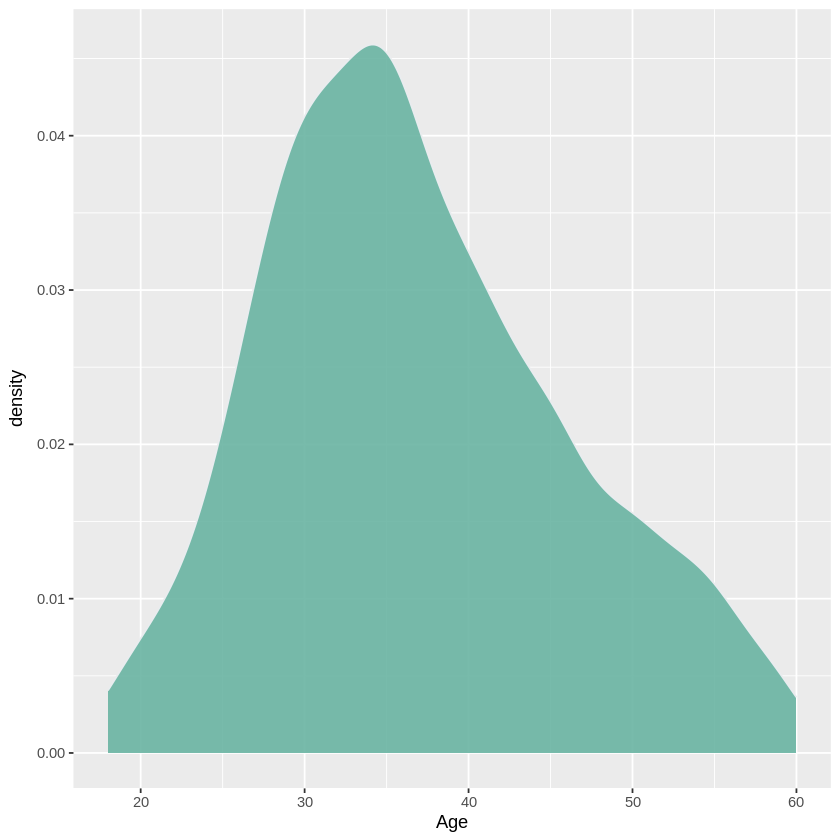

In [358]:
HREmployeeDF %>%
  filter( Age >=18 ) %>%
  ggplot( aes(x=Age)) +
    geom_density(fill="#69b3a2", color="#e9ecef", alpha=0.9)

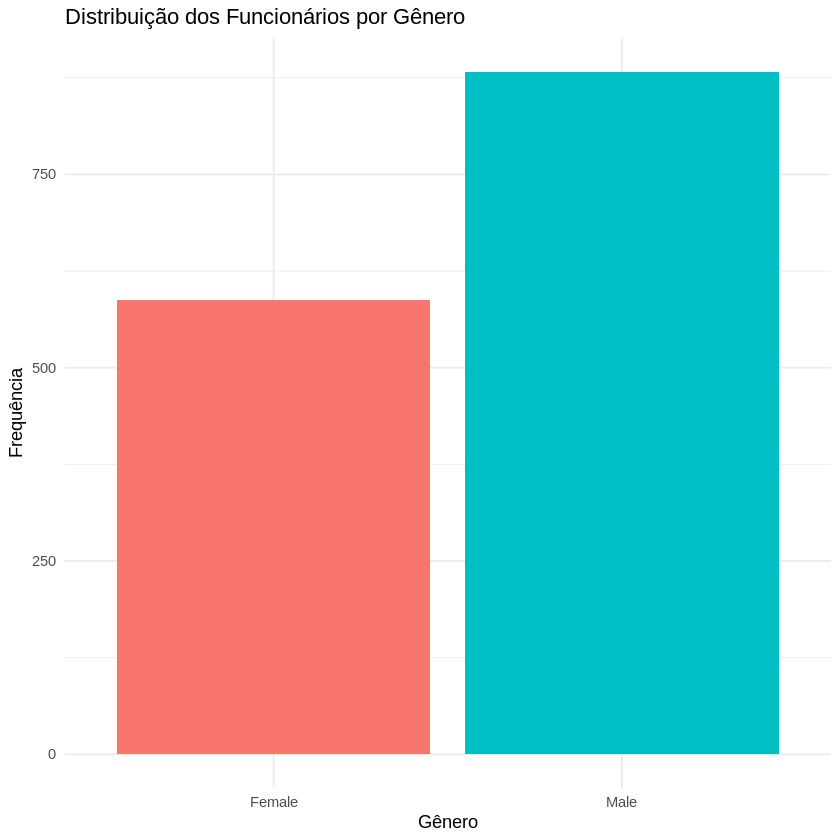

In [359]:

HREmployeeDF %>%
  ggplot(aes(x = Gender, fill = Gender )) +
  geom_bar() +
  labs(
    title = "Distribuição dos Funcionários por Gênero",
    x = "Gênero",
    y = "Frequência"
  ) +
  theme_minimal() +
  theme(legend.position = "none")

- Distribuiçao da Empresa por Genero em Percentagem.
     - Objectivo atingir os niveis de 50% Homens,50% Mulheres.

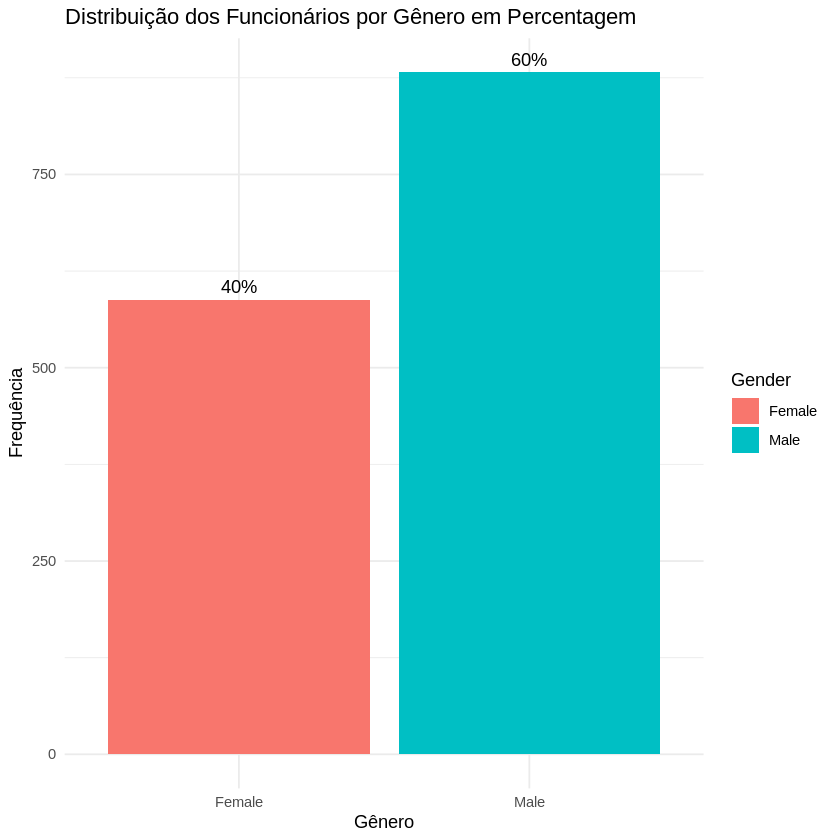

In [360]:

HREmployeeDF %>%
  ggplot(aes(x = Gender, fill = Gender)) +
  geom_bar() +
  geom_text(
    stat = "count",
    aes(label = percent(after_stat(count / sum(count)))),
    vjust = -0.5) +
  labs( title = "Distribuição dos Funcionários por Gênero em Percentagem",
    x = "Gênero",
    y = "Frequência") + theme_minimal()

 - Índice de Felicidade: se as pessoas são felizes
  balanço vida pessoal/profissional.


In [361]:
cor(HREmployeeDF$Age,HREmployeeDF$JobSatisfaction,method = "pearson")

[1] -0.004891877

In [362]:
HREmployeeDF %>%
  summarise(cor_Age_JobSatis =cor(Age,JobSatisfaction, method = "pearson"))

cor_Age_JobSatis
<dbl>
-0.004891877


In [363]:
HREmployeeDF%>%

summarise(corr_JobL_WorkLB=cor(JobLevel,WorkLifeBalance, method = "pearson"))

corr_JobL_WorkLB
<dbl>
0.03781775


In [364]:
cor(HREmployeeDF$JobLevel,HREmployeeDF$WorkLifeBalance, method = "pearson")

[1] 0.03781775

In [365]:
cor(HREmployeeDF$RelationshipSatisfaction,HREmployeeDF$WorkLifeBalance, method = "pearson")

[1] 0.01960441

In [366]:
cor(HREmployeeDF$Age,HREmployeeDF$RelationshipSatisfaction, method = "pearson")

[1] 0.05353472

In [367]:
cor(HREmployeeDF$Age,HREmployeeDF$YearsSinceLastPromotion, method = "pearson")

[1] 0.2165134

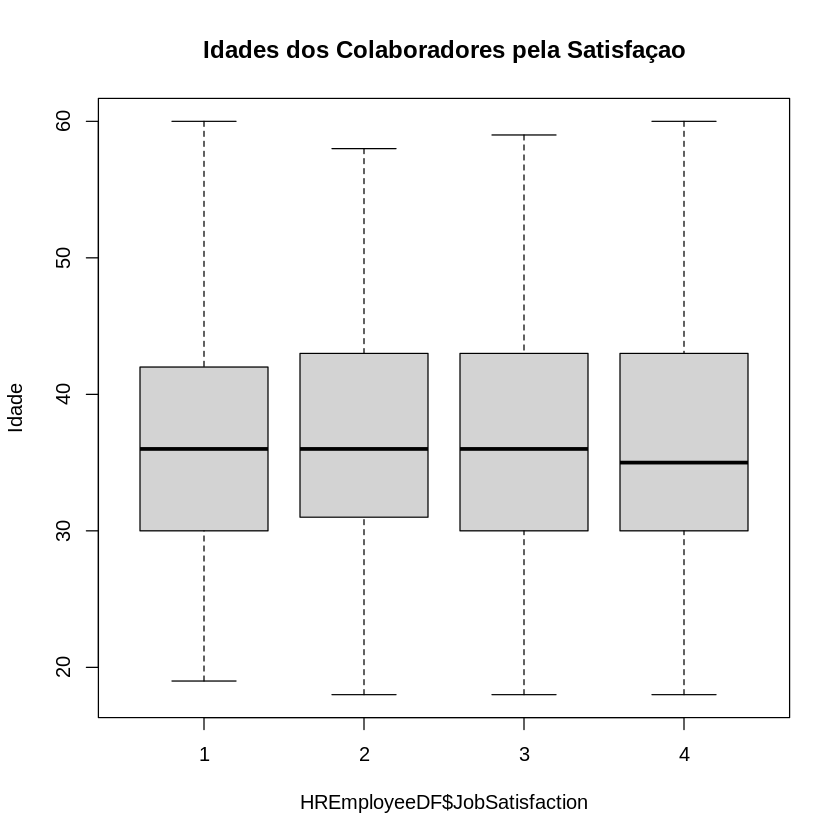

In [368]:
boxplot(HREmployeeDF$Age ~ HREmployeeDF$JobSatisfaction, main="Idades dos Colaboradores pela Satisfaçao",ylab = "Idade")

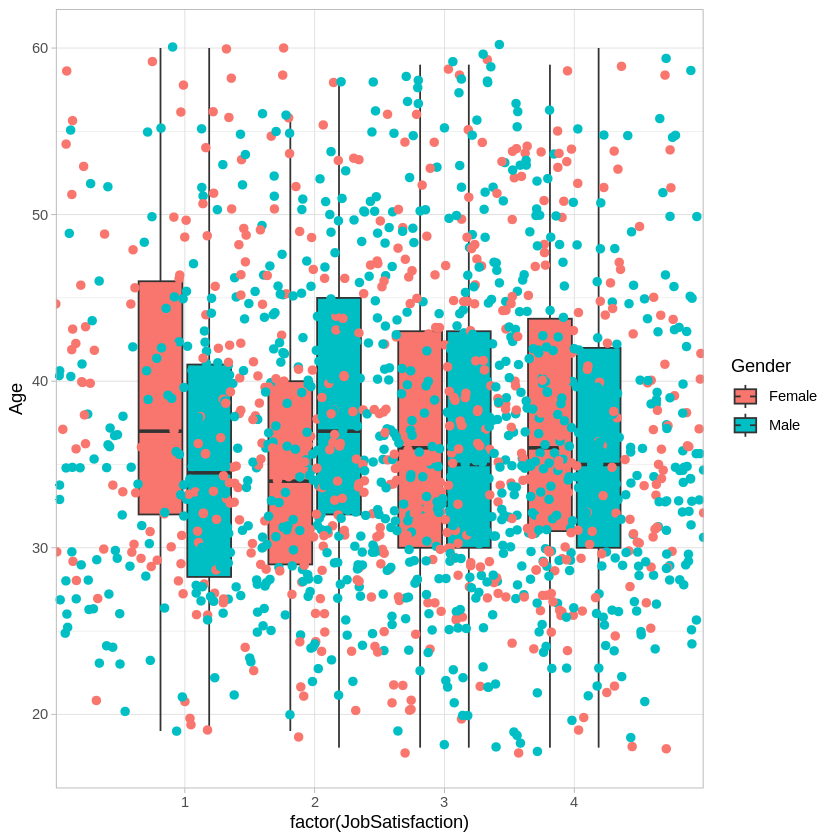

In [369]:
HREmployeeDF %>%
  ggplot(aes(x = factor(JobSatisfaction),
             y = Age,
             fill = Gender)) +
  geom_boxplot(alpha = 3, outlier.shape = NA) +
  geom_jitter(aes(color = Gender),
              width = 1,
              alpha = 5,
              size = 2) +
  theme_light()

In [370]:
Performance_Analysis <-HREmployeeDF %>%
  count(JobSatisfaction)


**- Carregamento dos Dados da Pesquisa do Bem Estar dos Trabalhadores.**

In [371]:
SurveyPPTableDF <- read_excel("/content/SurveyPingPongTable.xlsx")

In [372]:
summary(SurveyPPTableDF)

 employee_number environment_satisfaction job_involvement job_satisfaction
 Min.   :   2    Min.   :1.000            Min.   :3.000   Min.   :1.000   
 1st Qu.: 483    1st Qu.:2.000            1st Qu.:3.000   1st Qu.:2.000   
 Median :1022    Median :2.000            Median :3.000   Median :3.000   
 Mean   :1028    Mean   :1.828            Mean   :3.397   Mean   :2.448   
 3rd Qu.:1574    3rd Qu.:2.000            3rd Qu.:4.000   3rd Qu.:3.000   
 Max.   :2068    Max.   :2.000            Max.   :4.000   Max.   :3.000   
 relationship_satisfaction work_life_balance
 Min.   :1.000             Min.   :1.000    
 1st Qu.:2.000             1st Qu.:2.000    
 Median :3.000             Median :3.000    
 Mean   :2.781             Mean   :2.734    
 3rd Qu.:3.000             3rd Qu.:4.000    
 Max.   :4.000             Max.   :4.000    

In [382]:
head.matrix(SurveyPPTableDF)

employee_number,environment_satisfaction,job_involvement,job_satisfaction,relationship_satisfaction,work_life_balance
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
699,2,4,2,3,3
643,2,4,2,3,4
615,2,4,1,3,3
534,2,4,1,3,3
530,2,4,1,3,3
496,2,4,2,3,3


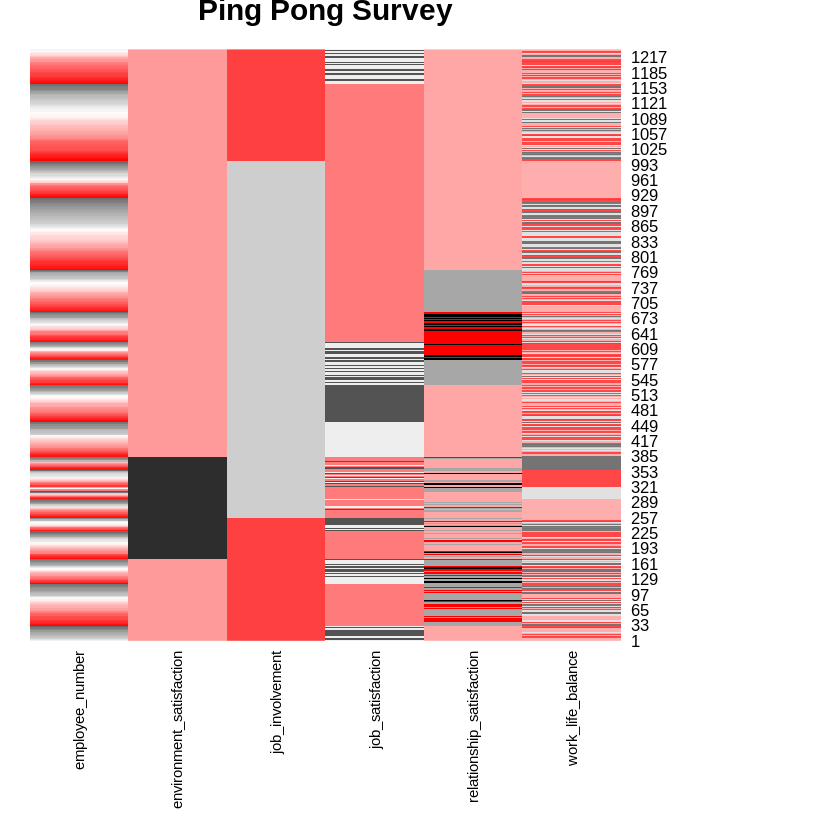

In [388]:
MSurveyPPTable <- as.matrix(SurveyPPTableDF)
heatmap(MSurveyPPTable, Rowv = NA, Colv = NA,scale = "column",
        col = colorRampPalette(c("black", "white", "red"))(80)
        , main ="Ping Pong Survey",
        margins = c(10, 10), cexRow = 1,cexCol = 0.9,    )

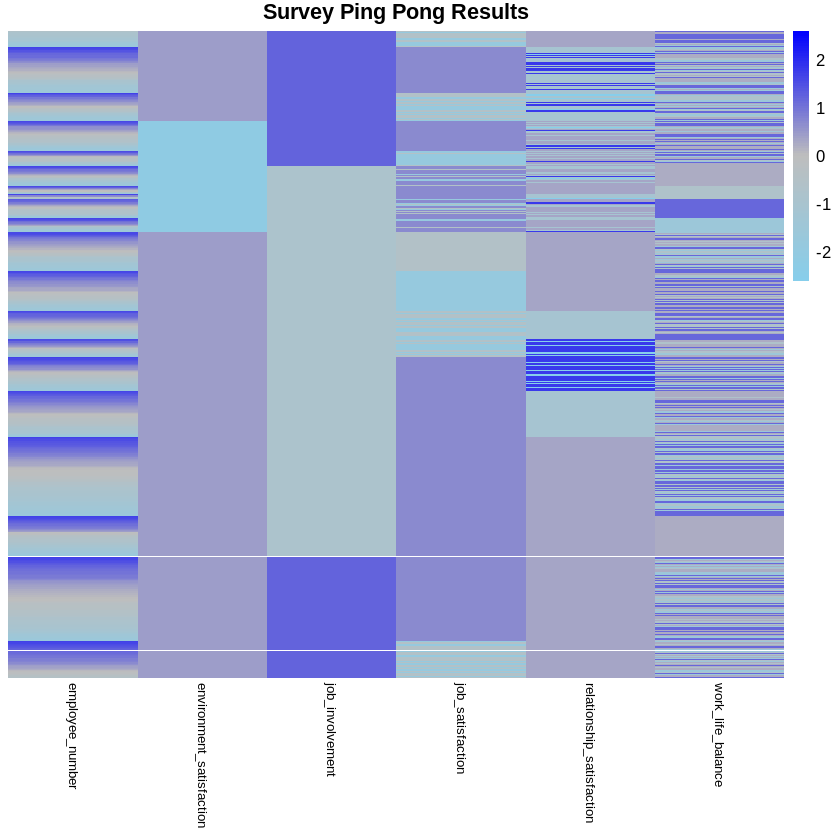

In [375]:
library(pheatmap)

pheatmap(MSurveyPPTable,
         scale = "column",
         cluster_rows = FALSE,
         cluster_cols = FALSE,
         color = colorRampPalette(c("skyblue", "grey", "blue"))(100),
         fontsize_row = 8,
         fontsize_col = 8,
         main = "Survey Ping Pong Results")